# Lab 4 — Tổng hợp tiếng nói (Mini TTS thông báo xếp hàng)

Notebook triển khai các phần A–G theo đề Lab 4. Dataset được đọc bằng đường dẫn tương đối `lab4_data/`, nên có thể đặt notebook cạnh thư mục dữ liệu hoặc đổi `PROJECT_ROOT` khi cần.

> **Backend HMM/neural:** Đề yêu cầu các backend/model được đóng gói offline. Dataset starter hiện chỉ chứa inventory WAV, không có backend pretrained. Các cell E/F sẽ tự dò module backend cục bộ; nếu chưa có, chúng ghi trạng thái “chưa khả dụng” thay vì tải model từ Internet.

**Cấu trúc khuyến nghị khi commit:** `Lab04.ipynb`, `lab4_data/` (nếu quyền sử dụng dữ liệu cho phép), `requirements.txt`.

## Task A — Text normalization, inventory và thống kê

Chuỗi số được đọc từng chữ số như quy định case study (bao gồm số 0 ở đầu). Inventory sẽ được kiểm tra metadata, sample rate, số kênh, duration và RMS; waveform được chuyển mono/16 kHz và RMS mục tiêu khi nạp để tổng hợp.

In [1]:
from pathlib import Path
import re, sys, time, importlib, inspect, warnings
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# Notebook chạy từ thư mục project; nếu mở ở nơi khác, sửa PROJECT_ROOT tại đây.
_cwd = Path.cwd().resolve()
_project_candidates = [_cwd] + [p for p in _cwd.iterdir() if p.is_dir() and (p / "lab4_data").is_dir()]
PROJECT_ROOT = next((p for p in _project_candidates if (p / "lab4_data").exists()), _cwd)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "lab4_data"
OUTPUT_DIR = PROJECT_ROOT / "audio_output"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
SR = 16_000
RMS_TARGET = 0.08
DIGIT_TO_WORD = {"0":"không", "1":"một", "2":"hai", "3":"ba", "4":"bốn", "5":"năm", "6":"sáu", "7":"bảy", "8":"tám", "9":"chín"}
assert DATA_DIR.exists(), f"Không thấy {DATA_DIR}. Đặt lab4_data cạnh notebook hoặc cập nhật PROJECT_ROOT."
metadata = pd.read_csv(DATA_DIR / "metadata.csv")
metadata.head()

,label,unit_id,candidate,speaker,duration_sec,rms,file_path,sample_rate,channels,bit_depth,voice,speed_wpm,pitch_setting,source
0,mời,moi,1,espeak_vi_synthetic,0.4546,0.08,units/moi/moi_01.wav,16000,1,16,vi,145,50,synthetic_espeak
1,mời,moi,2,espeak_vi_synthetic,0.4324,0.08,units/moi/moi_02.wav,16000,1,16,vi,155,53,synthetic_espeak
2,khách,khach,1,espeak_vi_synthetic,0.3448,0.08,units/khach/khach_01.wav,16000,1,16,vi,145,50,synthetic_espeak
3,khách,khach,2,espeak_vi_synthetic,0.3367,0.08,units/khach/khach_02.wav,16000,1,16,vi,155,53,synthetic_espeak
4,hàng,hang,1,espeak_vi_synthetic,0.4637,0.08,units/hang/hang_01.wav,16000,1,16,vi,145,50,synthetic_espeak


In [2]:
def normalize_text(text):
    """Lowercase, chuẩn hóa dấu câu và đọc mọi chuỗi số theo từng chữ số."""
    text = str(text).lower()
    text = re.sub(r"[^\w\sÀ-ỹĐđ]", " ", text, flags=re.UNICODE)
    tokens = []
    for token in text.split():
        tokens.extend(DIGIT_TO_WORD[c] for c in token if c.isdigit()) if token.isdigit() else tokens.append(token)
    return tokens

def rms(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.sqrt(np.mean(x*x) + 1e-12))

def load_unit(path, sr=SR, target_rms=RMS_TARGET):
    x, fs = sf.read(path, dtype="float32", always_2d=True)
    x = x.mean(axis=1)
    if fs != sr:
        g = np.gcd(fs, sr)
        x = signal.resample_poly(x, sr//g, fs//g).astype(np.float32)
    if target_rms is not None:
        x = x * (target_rms / max(rms(x), 1e-8))
        x = np.clip(x, -0.99, 0.99)
    return x

# Validate expected inventory and metadata against actual WAV files.
metadata["resolved_path"] = metadata.file_path.map(lambda p: DATA_DIR / p)
metadata["exists"] = metadata.resolved_path.map(Path.exists)
assert metadata.exists.all(), "Có WAV bị thiếu; kiểm tra file_path trong metadata.csv"
assert metadata.unit_id.nunique() >= 15, "Inventory cần ít nhất 15 units"
assert metadata.groupby("unit_id").size().min() >= 2, "Một số unit thiếu candidate thứ hai"
def wav_duration(path):
    info = sf.info(path)
    return info.frames / info.samplerate

metadata["measured_duration_sec"] = metadata.resolved_path.map(wav_duration)
metadata["measured_rms"] = metadata.resolved_path.map(lambda p: rms(sf.read(p, dtype="float32")[0]))
print(f"{metadata.unit_id.nunique()} units, {len(metadata)} WAV candidates; target Fs={SR} Hz")
metadata[["label", "unit_id", "candidate", "duration_sec", "rms", "measured_duration_sec", "measured_rms"]].head()

16 units, 32 WAV candidates; target Fs=16000 Hz


,label,unit_id,candidate,duration_sec,rms,measured_duration_sec,measured_rms
0,mời,moi,1,0.4546,0.08,0.454562,0.08
1,mời,moi,2,0.4324,0.08,0.432375,0.08
2,khách,khach,1,0.3448,0.08,0.344750,0.08
3,khách,khach,2,0.3367,0.08,0.336750,0.08
4,hàng,hang,1,0.4637,0.08,0.463687,0.08


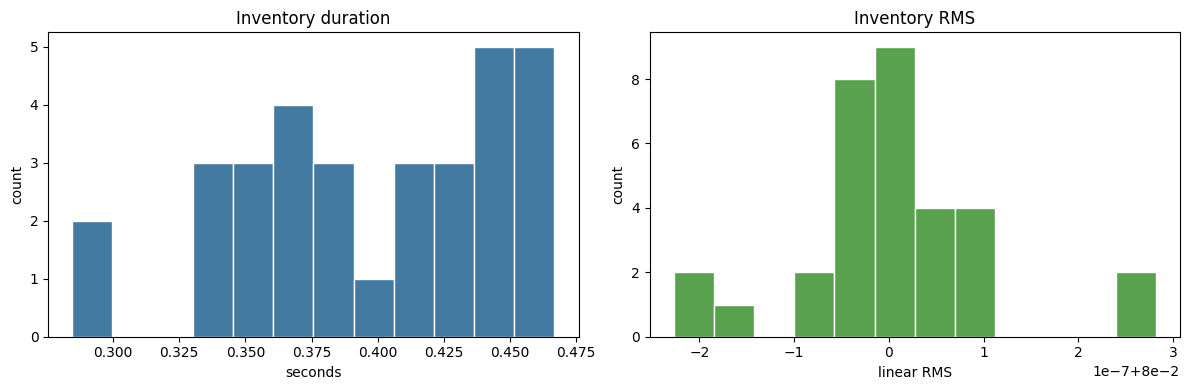

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(metadata.measured_duration_sec, bins=12, color="#427aa1", edgecolor="white"); ax[0].set(title="Inventory duration", xlabel="seconds", ylabel="count")
ax[1].hist(metadata.measured_rms, bins=12, color="#59a14f", edgecolor="white"); ax[1].set(title="Inventory RMS", xlabel="linear RMS", ylabel="count")
plt.tight_layout()
fig.savefig(FIG_DIR / "inventory_stats.png", dpi=180, bbox_inches="tight")

In [4]:
examples = pd.read_csv(DATA_DIR / "text_normalization_examples.csv")
for row in examples.itertuples():
    actual = normalize_text(row.input_text)
    expected = row.expected_tokens.split("|")
    print(row.input_text, "\n ->", actual, "| expected match:", actual == expected)
    assert actual == expected

Mời khách hàng số 23 đến quầy 5. 
 -> ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm'] | expected match: True
Mời khách hàng số 08 đến quầy 2. 
 -> ['mời', 'khách', 'hàng', 'số', 'không', 'tám', 'đến', 'quầy', 'hai'] | expected match: True
Mời khách hàng số 15 đến quầy 9. 
 -> ['mời', 'khách', 'hàng', 'số', 'một', 'năm', 'đến', 'quầy', 'chín'] | expected match: True


## Task B — Baseline concatenation

Baseline chọn candidate `01` cố định và ghép thẳng (cross-fade 0 ms). Các dấu biên được tính trên waveform đã nối để đánh dấu trên waveform và spectrogram. Click/continuity được xem xét qua bước nhảy mẫu, RMS quanh biên và phổ hai phía.

In [5]:
TEST_SENTENCES = [
    "Mời khách hàng số 23 đến quầy 5.",
    "Mời khách hàng số 08 đến quầy 2.",
    "Mời khách hàng số 15 đến quầy 9.",
]

def candidates_for(token):
    rows = metadata[metadata.label == token]
    if rows.empty:
        raise KeyError(f"Token '{token}' không có trong inventory")
    return [(r.candidate, DATA_DIR / r.file_path) for r in rows.itertuples()]

def make_raw_concat(tokens, candidate="01"):
    xs, selected = [], []
    for token in tokens:
        choices = candidates_for(token)
        match = next((p for c,p in choices if str(c) == candidate), choices[0][1])
        xs.append(trim_unit_context(load_unit(match))); selected.append(match)
    y = np.concatenate(xs)
    boundaries = np.cumsum([len(x) for x in xs])[:-1]
    return y, boundaries, selected

def trim_unit_context(x, keep_ms=10, frame_ms=5, threshold_ratio=0.08):
    """Remove long leading/trailing silence and retain a short consonant context."""
    x=np.asarray(x,dtype=np.float32)
    frame=max(16,int(SR*frame_ms/1000)); hop=max(8,frame//2)
    if len(x)<frame: return x
    energies=[]; starts=range(0,len(x)-frame+1,hop)
    for start in starts: energies.append(rms(x[start:start+frame]))
    peak=max(energies,default=0.0); active=np.flatnonzero(np.asarray(energies)>max(peak*threshold_ratio,1e-5))
    if not len(active): return x
    first=max(0,int(active[0]*hop)-int(SR*keep_ms/1000))
    last=min(len(x),int(active[-1]*hop)+frame+int(SR*keep_ms/1000))
    return x[first:last]

def save_audio(name, y, sr=SR):
    sf.write(OUTPUT_DIR / name, np.asarray(y, dtype=np.float32), sr)

base_tokens = normalize_text(TEST_SENTENCES[0])
raw, raw_bounds, raw_paths = make_raw_concat(base_tokens)
save_audio("raw_concat.wav", raw)
print("Tokens:", base_tokens, "| duration:", round(len(raw)/SR, 2), "s")
display(Audio(raw, rate=SR))

Tokens: ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm'] | duration: 2.21 s


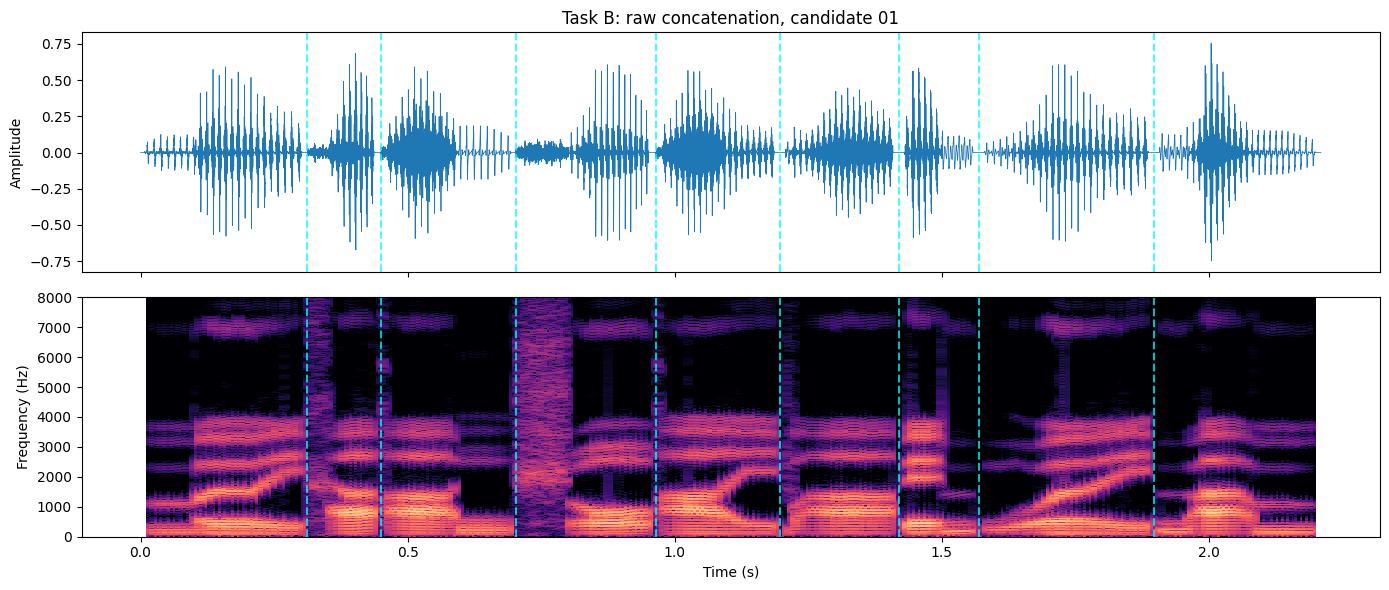

In [6]:
def plot_wave_spec(y, boundaries=(), title="", max_seconds=None):
    shown = y if max_seconds is None else y[:int(max_seconds*SR)]
    fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    t = np.arange(len(shown))/SR
    ax[0].plot(t, shown, linewidth=.55); ax[0].set_ylabel("Amplitude"); ax[0].set_title(title)
    f, tt, S = signal.spectrogram(shown, fs=SR, nperseg=400, noverlap=320, nfft=512)
    ax[1].pcolormesh(tt, f, 10*np.log10(S+1e-12), shading="auto", cmap="magma", vmin=-100, vmax=-30)
    ax[1].set_ylabel("Frequency (Hz)"); ax[1].set_xlabel("Time (s)"); ax[1].set_ylim(0, 8000)
    for b in boundaries:
        if b/SR <= (len(shown)/SR):
            for a in ax: a.axvline(b/SR, color="cyan", linestyle="--", alpha=.75)
    plt.tight_layout()
plot_wave_spec(raw, raw_bounds, "Task B: raw concatenation, candidate 01")
plt.savefig(FIG_DIR / "baseline_raw_waveform_spectrogram.png", dpi=180, bbox_inches="tight")

In [7]:
def boundary_metrics(y, bounds, sr=SR, window_ms=10):
    n = max(2, int(sr*window_ms/1000)); rows=[]
    for b in bounds:
        left, right = y[max(0,b-n):b], y[b:min(len(y),b+n)]
        rows.append({"boundary_sample":int(b), "time_sec":b/sr,
                     "sample_jump":float(abs(y[b]-y[b-1])),
                     "left_rms":rms(left), "right_rms":rms(right),
                     "rms_delta":abs(rms(left)-rms(right))})
    return pd.DataFrame(rows)
raw_boundary_table = boundary_metrics(raw, raw_bounds)
raw_boundary_table.describe()

,boundary_sample,time_sec,sample_jump,left_rms,right_rms,rms_delta
count,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000
mean,17030.000000,1.064375,0.003372,0.000276,0.008017,0.007741
std,8923.900492,0.557744,0.005432,0.000779,0.008871,0.008600
min,5000.000000,0.312500,0.000000,0.000001,0.000001,0.000000
25%,10230.000000,0.639375,0.000000,0.000001,0.000001,0.000000
50%,17300.000000,1.081250,0.000504,0.000001,0.005566,0.005565
75%,23320.000000,1.457500,0.004181,0.000001,0.016654,0.015000
max,30360.000000,1.897500,0.012848,0.002204,0.019395,0.019394


## Task C — Target/join cost, dynamic programming và smoothing

Target cost dùng độ lệch duration/RMS của candidate so với trung vị unit đó. Join cost là log-magnitude spectrum mismatch 25 ms ở hai phía ghép, cộng chênh RMS đã chuẩn hóa. Dynamic programming tối thiểu hóa tổng target cost + λ·join cost. Cross-fade thử 0/5/15/30 ms; do hai word unit có context silence, kết quả cần nghe và kiểm tra biên, không mặc định cross-fade dài hơn luôn tốt hơn.

DP total objective: 2.377846041277297


,position,token,candidate,path,target_cost,join_cost_from_previous
0,1,mời,2,units/moi/moi_02.wav,0.000626,NaN
1,2,khách,1,units/khach/khach_01.wav,0.000141,5.962646
2,3,hàng,1,units/hang/hang_01.wav,0.000139,1.192311
3,4,số,2,units/so/so_02.wav,0.000160,15.401423
4,5,hai,2,units/hai/hai_02.wav,0.000128,3.453577
5,6,ba,2,units/ba/ba_02.wav,0.000567,6.205408
6,7,đến,1,units/den/den_01.wav,0.000042,6.232763
7,8,quầy,1,units/quay/quay_01.wav,0.000561,2.897524
8,9,năm,2,units/nam/nam_02.wav,0.000508,6.153821


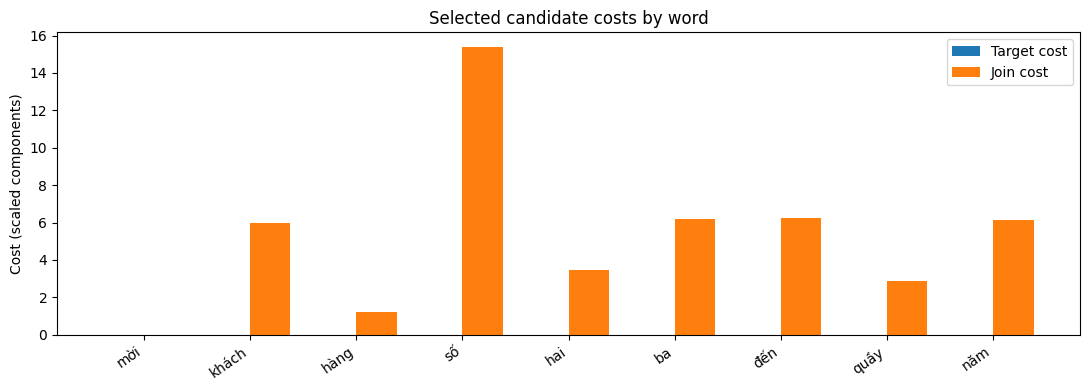

In [8]:
def active_edge_segment(x, side, n, frame_ms=5, threshold_ratio=0.08):
    frame=max(16,int(SR*frame_ms/1000)); hop=max(8,frame//2)
    energies=[rms(x[i:i+frame]) for i in range(0,max(1,len(x)-frame+1),hop)]
    peak=max(energies,default=0.0); active=np.flatnonzero(np.asarray(energies)>max(peak*threshold_ratio,1e-5))
    if not len(active): return x[-n:] if side=="end" else x[:n]
    first=int(active[0]*hop); last=min(len(x),int(active[-1]*hop)+frame)
    seg=x[max(0,last-n):last] if side=="end" else x[first:min(len(x),first+n)]
    return np.pad(seg,(max(0,n-len(seg)),0) if side=="end" else (0,max(0,n-len(seg))))

def log_spectrum(x, side, ms=25, nfft=512):
    n=max(16,int(SR*ms/1000)); seg=active_edge_segment(x,side,n)
    return 20*np.log10(np.maximum(np.abs(np.fft.rfft(seg*np.hanning(n),n=nfft)),1e-8))

def join_cost(a, b, ms=25):
    spec = float(np.mean((log_spectrum(a,"end",ms)-log_spectrum(b,"start",ms))**2))
    n=max(16,int(SR*ms/1000))
    left=active_edge_segment(a,"end",n); right=active_edge_segment(b,"start",n)
    er=abs(rms(left)-rms(right))/max(RMS_TARGET,1e-6)
    return spec/100.0 + 0.1*er**2

def target_cost(token, candidate_path, duration_weight=1.0, rms_weight=0.5):
    group = metadata[metadata.label == token]
    ref_d = float(group.duration_sec.median()); ref_r = float(group.rms.median())
    row = metadata[metadata.file_path == candidate_path.relative_to(DATA_DIR).as_posix()].iloc[0]
    d = float(row.duration_sec); r = float(row.rms)
    return duration_weight*((d-ref_d)/max(ref_d,1e-6))**2 + rms_weight*((r-ref_r)/max(ref_r,1e-6))**2

def select_units_dp(tokens, join_weight=0.05):
    options = [[(str(c),p,trim_unit_context(load_unit(p))) for c,p in candidates_for(t)] for t in tokens]
    costs = [np.array([target_cost(tokens[0],p) for _,p,_ in options[0]], dtype=float)]
    back = []
    for i in range(1,len(tokens)):
        cur = np.full(len(options[i]), np.inf); prev_idx=np.zeros(len(options[i]),dtype=int)
        for j,(_,_,x) in enumerate(options[i]):
            vals = [costs[-1][k] + join_weight*join_cost(options[i-1][k][2],x) for k in range(len(options[i-1]))]
            best=int(np.argmin(vals)); cur[j]=vals[best]+target_cost(tokens[i],options[i][j][1]); prev_idx[j]=best
        costs.append(cur); back.append(prev_idx)
    idx=int(np.argmin(costs[-1])); path=[idx]
    for ptr in reversed(back): path.append(int(ptr[path[-1]]))
    path=path[::-1]
    selected=[options[i][j] for i,j in enumerate(path)]
    return selected, float(np.min(costs[-1]))

def crossfade(a,b,n):
    n=min(int(n),len(a),len(b))
    if n<=0: return np.concatenate([a,b])
    alpha=np.linspace(0,1,n,endpoint=True,dtype=np.float32)
    return np.concatenate([a[:-n], (1-alpha)*a[-n:]+alpha*b[:n], b[n:]])

def concatenate_selected(selected, xfade_ms=0):
    y=selected[0][2].copy(); bounds=[]; n=int(SR*xfade_ms/1000)
    for _,_,x in selected[1:]:
        old_len=len(y); overlap=min(n,len(y),len(x))
        y=crossfade(y,x,overlap)
        bounds.append(old_len-overlap//2)
    return y, np.asarray(bounds,dtype=int)

selected, dp_total_cost = select_units_dp(base_tokens)
best, best_bounds = concatenate_selected(selected, xfade_ms=15)
save_audio("best_concat.wav", best)
selection_table=pd.DataFrame([{"position":i,"token":t,"candidate":c,"path":p.relative_to(DATA_DIR).as_posix(),"target_cost":target_cost(t,p)} for i,(t,(c,p,_)) in enumerate(zip(base_tokens,selected),1)])
selection_table["join_cost_from_previous"]=[np.nan]+[join_cost(selected[i-1][2],selected[i][2]) for i in range(1,len(selected))]
print("DP total objective:", dp_total_cost)
selection_table.to_csv(OUTPUT_DIR / "unit_selection_costs.csv", index=False)
fig,ax=plt.subplots(figsize=(11,4))
positions=np.arange(len(selection_table)); width=0.38
ax.bar(positions-width/2,selection_table.target_cost,width,label="Target cost")
ax.bar(positions+width/2,selection_table.join_cost_from_previous.fillna(0),width,label="Join cost")
ax.set_xticks(positions,selection_table.token,rotation=35,ha="right"); ax.set_ylabel("Cost (scaled components)"); ax.set_title("Selected candidate costs by word"); ax.legend(); plt.tight_layout()
fig.savefig(FIG_DIR / "unit_selection_join_cost.png",dpi=180,bbox_inches="tight")
selection_table

In [9]:
crossfade_results=[]
for ms in [0,5,15,30]:
    y,b=concatenate_selected(selected,ms)
    save_audio(f"concat_xfade_{ms}ms.wav", y)
    bm=boundary_metrics(y,b)
    crossfade_results.append({"xfade_ms":ms,"duration_sec":len(y)/SR,"mean_sample_jump":bm.sample_jump.mean(),"mean_rms_delta":bm.rms_delta.mean()})
xfade_table=pd.DataFrame(crossfade_results)
xfade_table.to_csv(OUTPUT_DIR/"crossfade_metrics.csv",index=False)
xfade_table

,xfade_ms,duration_sec,mean_sample_jump,mean_rms_delta
0,0,2.1375,0.002838,0.007753
1,5,2.0975,0.002982,0.006810
2,15,2.0175,0.002182,0.035932
3,30,1.8975,0.020859,0.013878


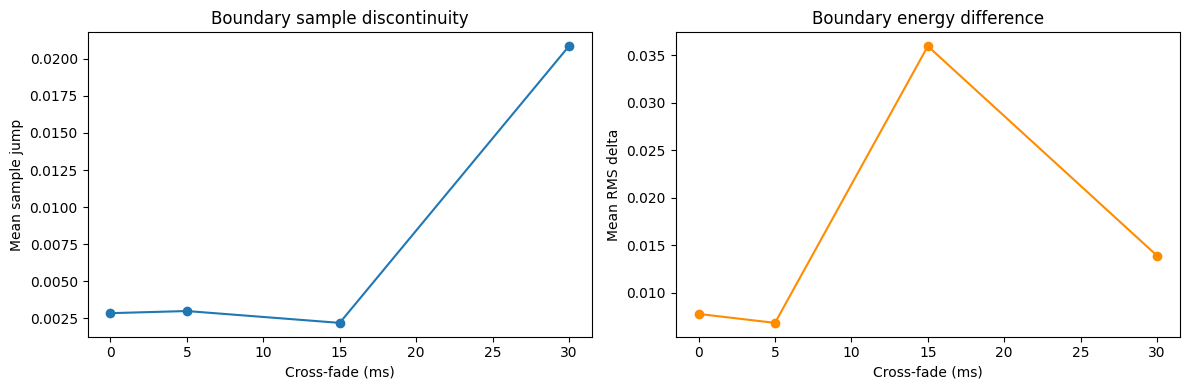

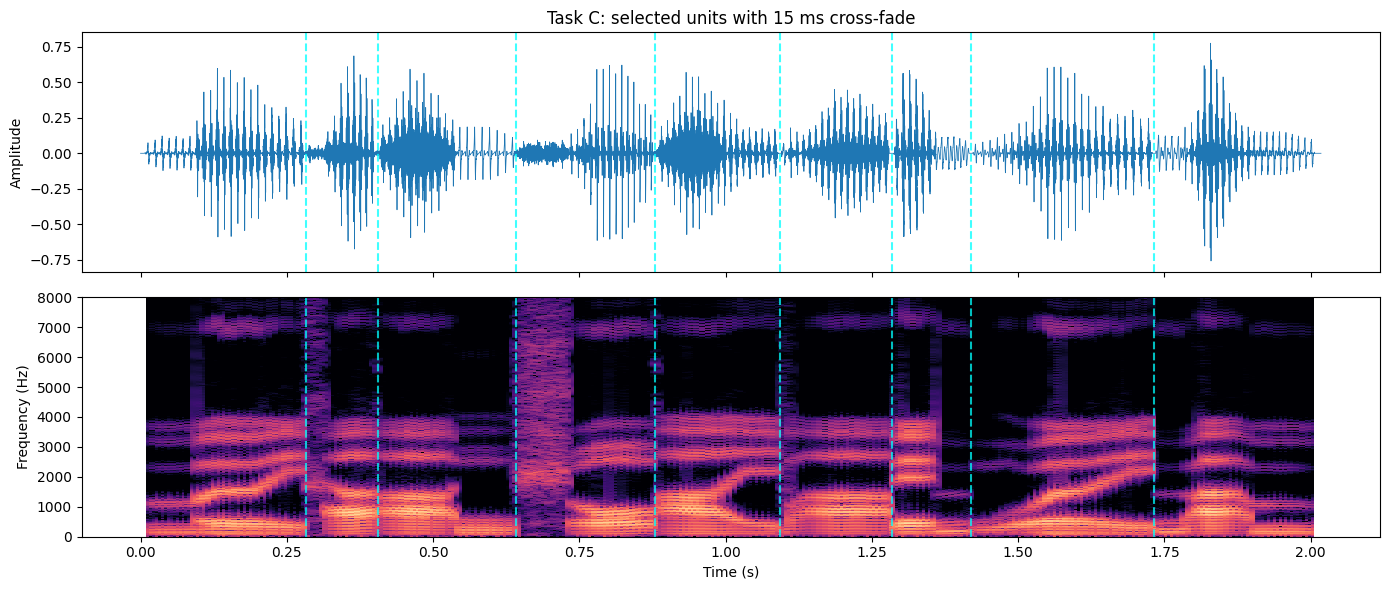

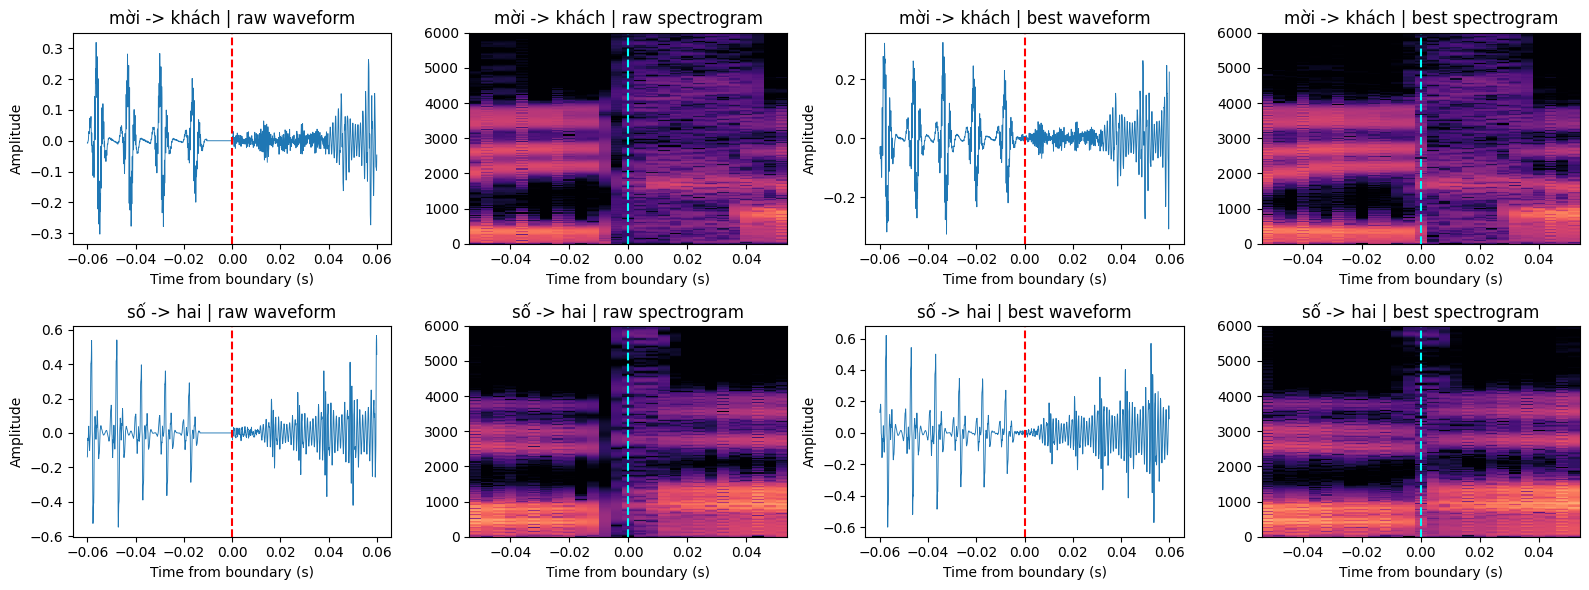

In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(xfade_table.xfade_ms,xfade_table.mean_sample_jump,"o-"); ax[0].set(xlabel="Cross-fade (ms)",ylabel="Mean sample jump",title="Boundary sample discontinuity")
ax[1].plot(xfade_table.xfade_ms,xfade_table.mean_rms_delta,"o-",color="darkorange"); ax[1].set(xlabel="Cross-fade (ms)",ylabel="Mean RMS delta",title="Boundary energy difference")
plt.tight_layout()
plt.savefig(FIG_DIR / "crossfade_comparison.png", dpi=180, bbox_inches="tight")
plot_wave_spec(best,best_bounds,"Task C: selected units with 15 ms cross-fade")
plt.savefig(FIG_DIR / "unit_selection_best_waveform_spectrogram.png", dpi=180, bbox_inches="tight")
# Compare two boundaries before and after smoothing, with waveform and spectrogram views.
example_indices=[0,3]; detail_rows=[]
fig,axes=plt.subplots(2,4,figsize=(16,6))
for row_idx,boundary_idx in enumerate(example_indices):
    token_pair=f"{base_tokens[boundary_idx]} -> {base_tokens[boundary_idx+1]}"
    for col_idx,(audio,bounds,label) in enumerate([(raw,raw_bounds,"raw"),(best,best_bounds,"best")]):
        center=int(bounds[boundary_idx]); half=int(0.06*SR); lo=max(0,center-half); hi=min(len(audio),center+half)
        clip=audio[lo:hi]; local_t=(np.arange(len(clip))+lo-center)/SR
        wave_ax=axes[row_idx,2*col_idx]; spec_ax=axes[row_idx,2*col_idx+1]
        wave_ax.plot(local_t,clip,linewidth=.65); wave_ax.axvline(0,color="red",linestyle="--"); wave_ax.set(title=f"{token_pair} | {label} waveform",xlabel="Time from boundary (s)",ylabel="Amplitude")
        ff,tt,SS=signal.spectrogram(clip,fs=SR,nperseg=256,noverlap=192,nfft=512)
        spec_ax.pcolormesh(tt-half/SR,ff,10*np.log10(SS+1e-12),shading="auto",cmap="magma",vmin=-100,vmax=-25); spec_ax.axvline(0,color="cyan",linestyle="--"); spec_ax.set(title=f"{token_pair} | {label} spectrogram",xlabel="Time from boundary (s)",ylim=(0,6000))
    detail_rows.append({"boundary":token_pair,"raw_sample_jump":float(abs(raw[raw_bounds[boundary_idx]]-raw[raw_bounds[boundary_idx]-1])),"best_sample_jump":float(abs(best[best_bounds[boundary_idx]]-best[best_bounds[boundary_idx]-1]))})
plt.tight_layout(); fig.savefig(FIG_DIR/"boundary_detail_before_after.png",dpi=180,bbox_inches="tight")
pd.DataFrame(detail_rows).to_csv(OUTPUT_DIR/"boundary_detail_metrics.csv",index=False)
display(Audio(best,rate=SR))

## Task D — Prosody, F0, duration và source–filter

Đo F0 bằng autocorrelation trên frame hữu thanh (có thể hiệu chỉnh `F0_MIN/MAX`). Thử duration 0.8×/1.0×/1.2× bằng phase vocoder và pitch −2/0/+2 semitone bằng `pitch_shift`; so sánh spectrogram. Trong source–filter, đổi F0 điều khiển chu kỳ nguồn kích thích, trong khi formant/spectral envelope chủ yếu do bộ lọc đường thanh quản quyết định.

Median voiced F0: 82.1 Hz


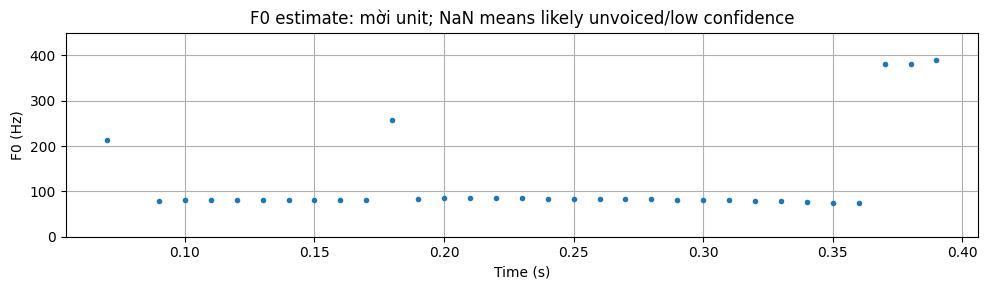

In [11]:
def estimate_f0_autocorr(x, sr=SR, fmin=70, fmax=400, frame_ms=40, hop_ms=10):
    frame=int(sr*frame_ms/1000); hop=int(sr*hop_ms/1000); out=[]; times=[]
    for start in range(0,max(1,len(x)-frame+1),hop):
        s=x[start:start+frame]
        if len(s)<frame: break
        s=(s-np.mean(s))*np.hanning(frame)
        ac=signal.correlate(s,s,mode="full",method="fft")[frame-1:]
        lo=max(1,int(sr/fmax)); hi=min(len(ac)-1,int(sr/fmin))
        k=lo+int(np.argmax(ac[lo:hi+1])); confidence=ac[k]/max(ac[0],1e-9)
        out.append(sr/k if confidence>0.25 else np.nan); times.append((start+frame/2)/sr)
    return np.asarray(times),np.asarray(out)

# Chọn candidate của unit "mời" làm ví dụ hữu thanh.
voice_path = candidates_for("mời")[0][1]
voice = load_unit(voice_path)
f0_t,f0 = estimate_f0_autocorr(voice)
plt.figure(figsize=(10,3)); plt.plot(f0_t,f0,"."); plt.ylim(0,450); plt.xlabel("Time (s)"); plt.ylabel("F0 (Hz)"); plt.title("F0 estimate: mời unit; NaN means likely unvoiced/low confidence"); plt.grid(True); plt.tight_layout(); plt.savefig(FIG_DIR / "prosody_f0_contour.png", dpi=180, bbox_inches="tight")
print("Median voiced F0:", round(float(np.nanmedian(f0)),1), "Hz")

In [12]:
from fractions import Fraction

def phase_vocoder_stretch(x, rate, n_fft=1024, hop=256):
    """Fast phase-vocoder time stretch. rate > 1 shortens audio; pitch is approximately preserved."""
    x=np.asarray(x,dtype=np.float32)
    if np.isclose(rate,1.0): return x.copy()
    _,_,z=signal.stft(x,fs=SR,nperseg=n_fft,noverlap=n_fft-hop,boundary="zeros",padded=True)
    steps=np.arange(0,z.shape[1]-1,rate)
    bins=np.arange(n_fft//2+1)
    phase_advance=2*np.pi*hop*bins/n_fft
    phase=np.angle(z[:,0]); out=np.empty((z.shape[0],len(steps)),dtype=np.complex64)
    for j,t in enumerate(steps):
        i=int(t); frac=t-i
        mag=(1-frac)*np.abs(z[:,i])+frac*np.abs(z[:,i+1])
        delta=np.angle(z[:,i+1])-np.angle(z[:,i])-phase_advance
        delta-=2*np.pi*np.round(delta/(2*np.pi))
        phase+=phase_advance+delta
        out[:,j]=mag*np.exp(1j*phase)
    _,y=signal.istft(out,fs=SR,nperseg=n_fft,noverlap=n_fft-hop,input_onesided=True,boundary=True)
    target=max(1,int(round(len(x)/rate)))
    return np.pad(y[:target],(0,max(0,target-len(y)))).astype(np.float32)

def pitch_shift_phase_vocoder(x,semitones):
    ratio=2**(semitones/12)
    frac=Fraction(1/ratio).limit_denominator(100)
    shifted=signal.resample_poly(x,frac.numerator,frac.denominator).astype(np.float32)
    return phase_vocoder_stretch(shifted,rate=1/ratio)

prosody_audio={}
for duration_scale in [0.8,1.0,1.2]:
    y=phase_vocoder_stretch(best,rate=1/duration_scale)
    prosody_audio[f"duration_{duration_scale:.1f}x"]=y
    save_audio(f"duration_{duration_scale:.1f}x.wav",y)
for semitones in [-2,0,2]:
    y=pitch_shift_phase_vocoder(best,semitones)
    prosody_audio[f"pitch_{semitones:+d}st"]=y
    save_audio(f"pitch_{semitones:+d}st.wav",y)
print("Duration variants:", {k:round(len(v)/SR,2) for k,v in prosody_audio.items() if "duration" in k})
print("Pitch-shift files saved; listen and compare formant preservation/artifacts.")

Duration variants: {'duration_0.8x': 1.61, 'duration_1.0x': 2.02, 'duration_1.2x': 2.42}
Pitch-shift files saved; listen and compare formant preservation/artifacts.


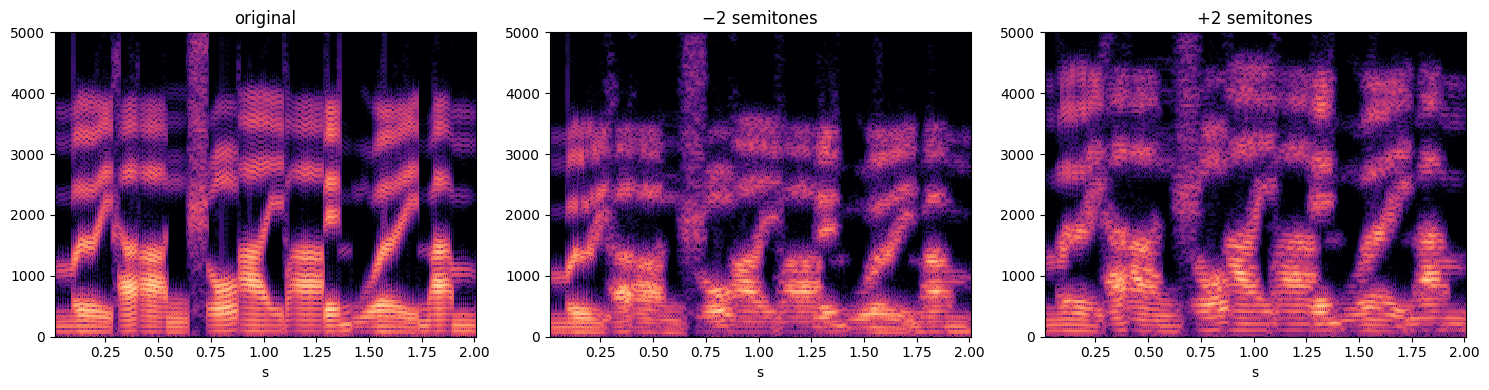

In [13]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
for a,(name,y) in zip(ax,[("original",best),("−2 semitones",prosody_audio["pitch_-2st"]),("+2 semitones",prosody_audio["pitch_+2st"])]):
    f,t,S=signal.spectrogram(y,fs=SR,nperseg=400,noverlap=320,nfft=512)
    a.pcolormesh(t,f,10*np.log10(S+1e-12),shading="auto",cmap="magma",vmin=-100,vmax=-30); a.set(ylim=(0,5000),title=name,xlabel="s")
plt.tight_layout(); plt.savefig(FIG_DIR / "prosody_pitch_spectrograms.png", dpi=180, bbox_inches="tight")

## Task E — Quan sát HMM-based backend

Backend HMM cần được đóng gói cục bộ thành `hmm_tts_backend.py` với `synthesize_hmm(text) -> (waveform, sample_rate, tracks)`. Tracks cần có ít nhất `f0` và một trajectory spectral/formant (ví dụ `spectral` hoặc `formant`). Notebook không giả lập HMM bằng cách gắn nhãn cho unit-selection; nếu module chưa tồn tại, phần này được đánh dấu là yêu cầu môi trường còn thiếu.

In [14]:
hmm_result=None
try:
    hmm_mod=importlib.import_module("hmm_tts_backend")
    hmm_t0=time.perf_counter(); hmm_result=hmm_mod.synthesize_hmm(TEST_SENTENCES[0]); hmm_latency=time.perf_counter()-hmm_t0
    y_hmm,sr_hmm,tracks=hmm_result
    y_hmm=np.asarray(y_hmm,dtype=np.float32)
    save_audio("hmm_tts.wav",y_hmm,int(sr_hmm))
    print("HMM synthesis complete:",len(y_hmm)/sr_hmm,"seconds; tracks:",list(tracks))
except (ImportError, AttributeError, FileNotFoundError) as e:
    print("HMM backend unavailable:",e,"| Add offline hmm_tts_backend.py and rerun this cell.")

HMM synthesis complete: 3.465 seconds; tracks: ['f0', 'spectral', 'energy', 'state', 'word', 'frame_hz']


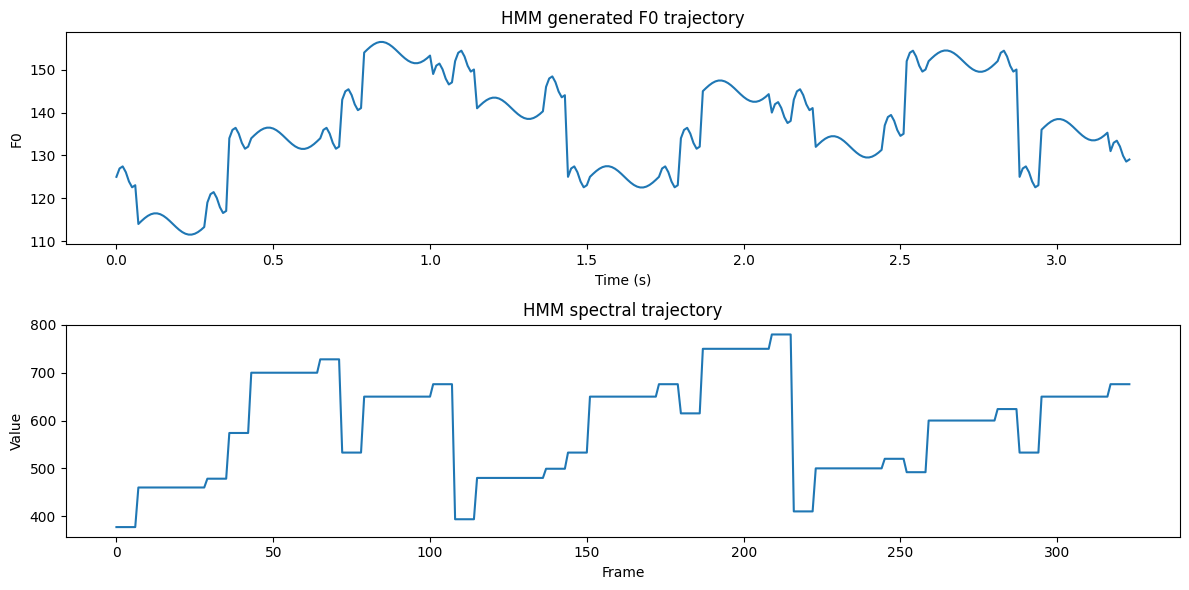

In [15]:
if hmm_result is not None:
    f0_track=np.asarray(tracks["f0"])
    spec_key=next((k for k in ["spectral","formant","spectral_parameter"] if k in tracks),None)
    fig,ax=plt.subplots(2 if spec_key else 1,1,figsize=(12,6),squeeze=False)
    ax[0,0].plot(np.arange(len(f0_track))*0.01,f0_track); ax[0,0].set(title="HMM generated F0 trajectory",xlabel="Time (s)",ylabel="F0")
    if spec_key:
        ax[1,0].plot(np.asarray(tracks[spec_key])); ax[1,0].set(title=f"HMM {spec_key} trajectory",xlabel="Frame",ylabel="Value")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "hmm_parameter_trajectories.png", dpi=180, bbox_inches="tight")
    pd.DataFrame({k: tracks[k] for k in ["f0", "spectral", "energy", "state", "word"]}).to_csv(PROJECT_ROOT / "hmm_demo" / "generated_tracks.csv", index=False)
    display(Audio(y_hmm,rate=sr_hmm))

## Task F — Neural TTS pretrained offline

Backend wrapper tùy chọn `neural_tts_backend.py` cần có `synthesize(text) -> (waveform, sample_rate, extra)`. Chạy cùng ba câu test, đo latency trên máy hiện tại và lưu WAV. Chỉ dùng model đã có sẵn offline; không tải model trong notebook. Mel được vẽ nếu `extra` trả về khóa `mel`.

In [16]:
neural_results=[]
try:
    nn_mod=importlib.import_module("neural_tts_backend")
    for i,text in enumerate(TEST_SENTENCES,1):
        t0=time.perf_counter(); y_nn,sr_nn,extra=nn_mod.synthesize(text); latency=time.perf_counter()-t0
        y_nn=np.asarray(y_nn,dtype=np.float32)
        if y_nn.ndim>1: y_nn=y_nn.mean(axis=1)
        save_audio(f"neural_tts_{i}.wav",y_nn,int(sr_nn))
        if i == 1: save_audio("neural_tts.wav",y_nn,int(sr_nn))
        neural_results.append({"sentence":text,"latency_sec":latency,"duration_sec":len(y_nn)/sr_nn,"sample_rate":sr_nn,"extra":extra})
    neural_summary=pd.DataFrame([{k:v for k,v in r.items() if k!="extra"} for r in neural_results])
    neural_summary.to_csv(OUTPUT_DIR/"neural_latency_results.csv",index=False)
    print(neural_summary)
except (ImportError, AttributeError, FileNotFoundError) as e:
    print("Neural TTS backend unavailable:",e,"| Add offline neural_tts_backend.py with local model and rerun.")

                           sentence  latency_sec  duration_sec  sample_rate
0  Mời khách hàng số 23 đến quầy 5.     4.998219      2.147846        22050
1  Mời khách hàng số 08 đến quầy 2.     0.098221      2.124626        22050
2  Mời khách hàng số 15 đến quầy 9.     0.100946      2.124626        22050


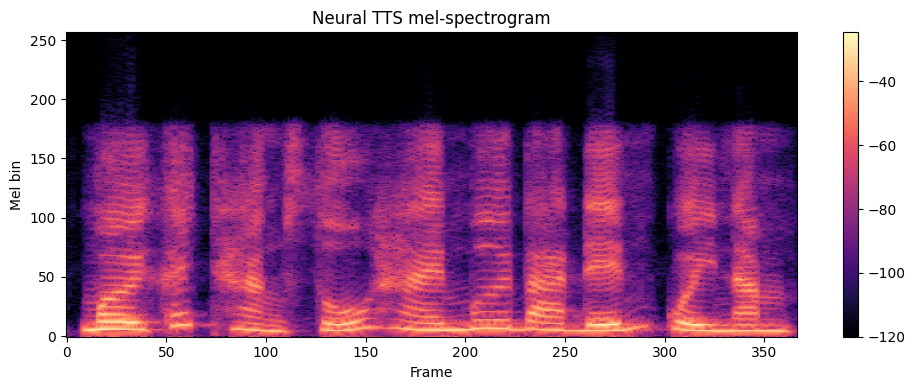

In [17]:
if neural_results:
    mel=neural_results[0]["extra"].get("mel") if isinstance(neural_results[0]["extra"],dict) else None
    if mel is not None:
        plt.figure(figsize=(10,4)); plt.imshow(np.asarray(mel),origin="lower",aspect="auto",cmap="magma"); plt.title("Neural TTS mel-spectrogram"); plt.xlabel("Frame"); plt.ylabel("Mel bin"); plt.colorbar(); plt.tight_layout(); plt.savefig(FIG_DIR / "neural_tts_mel_spectrogram.png", dpi=180, bbox_inches="tight")

## Task G — So sánh và đánh giá

Chạy listening test mù bằng cách ghi ratings trong `ratings.csv`. Điểm MOS/naturalness và intelligibility cần do người nghe nhập; notebook không tự bịa điểm. Bảng latency backend được tự điền ở những backend đã chạy. Các ô còn lại cần điền từ listening test, và resource size từ file/model thực tế.

Anonymous A/B/C audio files: 9 in audio_output/listening_test_audio


,duration_sec,latency_sec,rms,peak
method,,,,
Concatenation,1.998333,0.229823,0.08,0.590640
HMM demo,3.465000,0.077331,0.08,0.547177
Neural Piper,2.171104,0.111805,0.08,0.435793


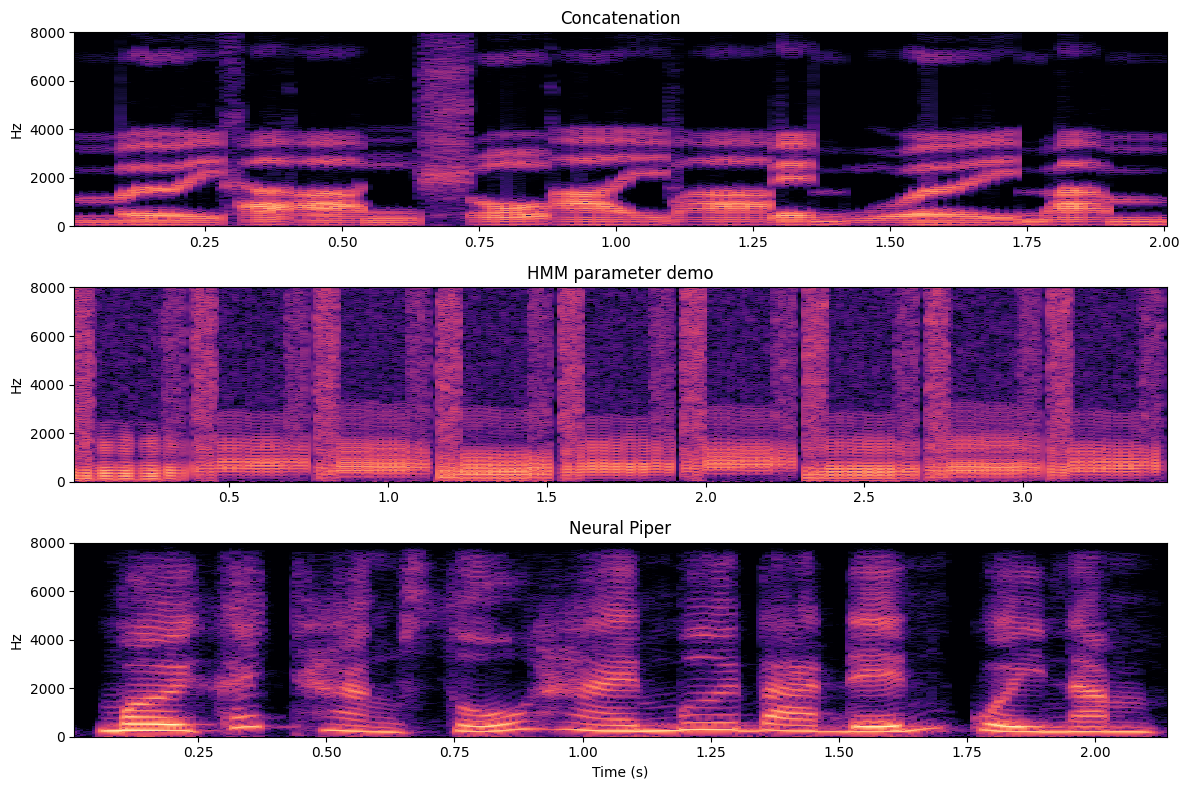

In [18]:
# Prepare a randomized, anonymous listening set: three sentences x three systems.
import random, shutil
LISTEN_DIR=OUTPUT_DIR/"listening_test_audio"; LISTEN_DIR.mkdir(exist_ok=True)
comparison_rows=[]; listening_key=[]; rng=random.Random(457)
for sentence_id,text in enumerate(TEST_SENTENCES,1):
    sentence_tokens=normalize_text(text)
    t0=time.perf_counter(); chosen,total=select_units_dp(sentence_tokens); y_concat,bounds=concatenate_selected(chosen,15); concat_latency=time.perf_counter()-t0
    t0=time.perf_counter(); y_h,sr_h,tracks_h=hmm_mod.synthesize_hmm(text); hmm_time=time.perf_counter()-t0
    t0=time.perf_counter(); y_n,sr_n,extra_n=nn_mod.synthesize(text); neural_time=time.perf_counter()-t0
    systems=[("Concatenation",y_concat,SR,concat_latency),("HMM demo",y_h,sr_h,hmm_time),("Neural Piper",y_n,sr_n,neural_time)]
    rng.shuffle(systems)
    for slot,(method,audio,fs,latency) in enumerate(systems,1):
        audio=np.asarray(audio,dtype=np.float32)
        if audio.ndim>1: audio=audio.mean(axis=1)
        if fs!=SR:
            g=np.gcd(fs,SR); audio=signal.resample_poly(audio,SR//g,fs//g).astype(np.float32)
        audio=audio*(0.08/max(rms(audio),1e-8)); audio=np.clip(audio,-0.99,0.99)
        audio_id=f"S{sentence_id}_A{slot}"
        sf.write(LISTEN_DIR/f"{audio_id}.wav",audio,SR)
        listening_key.append({"audio_id":audio_id,"sentence_id":sentence_id,"method":method})
        comparison_rows.append({"sentence_id":sentence_id,"method":method,"duration_sec":len(audio)/SR,"latency_sec":latency,"sample_rate":SR,"rms":rms(audio),"peak":float(np.max(np.abs(audio)))})
listening_key=pd.DataFrame(listening_key)
comparison_results=pd.DataFrame(comparison_rows)
listening_key.to_csv(OUTPUT_DIR/"listening_test_key.csv",index=False)
comparison_results.to_csv(OUTPUT_DIR/"comparison_results.csv",index=False)
print("Anonymous A/B/C audio files:",len(listening_key))
fig,ax=plt.subplots(3,1,figsize=(12,8))
y_neural,sr_neural=sf.read(OUTPUT_DIR/"neural_tts_1.wav",dtype="float32")
for a,(name,y,fs) in zip(ax,[("Concatenation",best,SR),("HMM parameter demo",y_hmm,sr_hmm),("Neural Piper",y_neural,sr_neural)]):
    f,t,S=signal.spectrogram(y,fs=fs,nperseg=512,noverlap=384,nfft=512)
    a.pcolormesh(t,f,10*np.log10(S+1e-12),shading="auto",cmap="magma",vmin=-100,vmax=-25); a.set(ylim=(0,8000),ylabel="Hz",title=name)
ax[-1].set_xlabel("Time (s)"); plt.tight_layout(); plt.savefig(FIG_DIR/"three_backend_spectrograms.png",dpi=180,bbox_inches="tight")
display(comparison_results.groupby("method")[["duration_sec","latency_sec","rms","peak"]].mean())

In [19]:
ratings_path=OUTPUT_DIR/"ratings.csv"
if ratings_path.exists():
    ratings=pd.read_csv(ratings_path)
    expected_columns=["listener_id","audio_id","intelligibility_correct_0_1","naturalness_1_5","continuity_1_5","notes"]
    if list(ratings.columns)!=expected_columns:
        ratings=pd.DataFrame(columns=expected_columns)
if ratings.empty:
    ratings=pd.DataFrame({"listener_id":[""]*len(listening_key),"audio_id":listening_key.audio_id,"intelligibility_correct_0_1":[""]*len(listening_key),"naturalness_1_5":[""]*len(listening_key),"continuity_1_5":[""]*len(listening_key),"notes":[""]*len(listening_key)})
ratings.to_csv(ratings_path,index=False)
print("Blind listening rating sheet:",ratings_path.relative_to(PROJECT_ROOT))
comparison=comparison_results.groupby("method",as_index=False).agg(duration_sec=("duration_sec","mean"),latency_sec=("latency_sec","mean"),rms=("rms","mean"),peak=("peak","mean"))
comparison["intelligibility"]="pending human ratings"
comparison["naturalness"]="pending MOS"
comparison["continuity"]="pending human ratings"
comparison["memory_data"]=[f"{sum(p.stat().st_size for p in (DATA_DIR / 'units').rglob('*.wav'))/1e6:.1f} MB inventory" if m=="Concatenation" else (f"{(PROJECT_ROOT / 'hmm_demo' / 'state_parameters.csv').stat().st_size/1e3:.1f} kB parameter table" if m=="HMM demo" else f"{(PROJECT_ROOT / 'models' / 'vi_VN-vais1000-medium.onnx').stat().st_size/1e6:.1f} MB ONNX") for m in comparison.method]
comparison

Blind listening rating sheet: audio_output/ratings.csv


,method,duration_sec,latency_sec,rms,peak,intelligibility,naturalness,continuity,memory_data
0,Concatenation,1.998333,0.229823,0.08,0.590640,pending human ratings,pending MOS,pending human ratings,0.4 MB inventory
1,HMM demo,3.465000,0.077331,0.08,0.547177,pending human ratings,pending MOS,pending human ratings,0.3 kB parameter table
2,Neural Piper,2.171104,0.111805,0.08,0.435793,pending human ratings,pending MOS,pending human ratings,63.2 MB ONNX


In [20]:
rating_columns=["intelligibility_correct_0_1","naturalness_1_5","continuity_1_5"]
for column in rating_columns: ratings[column]=pd.to_numeric(ratings[column],errors="coerce")
if ratings[rating_columns].notna().any().any():
    scored=ratings.merge(listening_key,on="audio_id",how="left")
    display(scored.groupby("method")[rating_columns].mean())
else:
    print("Ch?a c? l??t nghe ???c ch?m. G?i listening_test_audio/?n danh v? nh?p ?i?m v?o ratings.csv; notebook s? t?nh trung b?nh sau khi c? d? li?u.")

print("\nAudio outputs:")
for p in sorted(OUTPUT_DIR.glob("*.wav")): print(p.name, round(sf.info(p).duration,2),"s")
print("Blind listening files:",len(list(LISTEN_DIR.glob("*.wav"))))

Ch?a c? l??t nghe ???c ch?m. G?i listening_test_audio/?n danh v? nh?p ?i?m v?o ratings.csv; notebook s? t?nh trung b?nh sau khi c? d? li?u.

Audio outputs:
best_concat.wav 2.02 s
concat_xfade_0ms.wav 2.14 s
concat_xfade_15ms.wav 2.02 s
concat_xfade_30ms.wav 1.9 s
concat_xfade_5ms.wav 2.1 s
duration_0.8x.wav 1.61 s
duration_1.0x.wav 2.02 s
duration_1.2x.wav 2.42 s
hmm_tts.wav 3.46 s
neural_tts.wav 2.15 s
neural_tts_1.wav 2.15 s
neural_tts_2.wav 2.12 s
neural_tts_3.wav 2.12 s
pitch_+0st.wav 2.02 s
pitch_+2st.wav 2.02 s
pitch_-2st.wav 2.02 s
raw_concat.wav 2.21 s
Blind listening files: 9
